## Download et entrainement de dataset

In [1]:
import torch
import torch.nn as nn

torch.manual_seed(42)

# --------------------------------------------------
# 1. Créer les données
# --------------------------------------------------

serie = torch.sin(torch.linspace(0, 20, 200))
longueur_sequence = 10

X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

# Forme attendue : (nombre de séquences, longueur, variables)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]


# --------------------------------------------------
# 2. Définir le modèle LSTM
# --------------------------------------------------

class SimpleLSTM(nn.Module):
    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,     # Une variable à chaque instant
            hidden_size=16,   # 16 unités cachées
            num_layers=1,     # Une seule couche LSTM
            batch_first=True
        )

        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        # Sans états initiaux fournis, h₀ et c₀ sont mis à zéro.
        etats, (h_final, c_final) = self.lstm(x)

        # etats : (nombre de séquences, 10, 16)
        dernier_etat = etats[:, -1, :]  # (nombre de séquences, 16)

        # Une prédiction par séquence
        return self.sortie(dernier_etat)


modele = SimpleLSTM()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)


# --------------------------------------------------
# 3. Entraîner le modèle
# --------------------------------------------------

modele.train()

for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")


# --------------------------------------------------
# 4. Tester le modèle
# --------------------------------------------------

modele.eval()

with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.003562
Epoch 100 | Erreur : 0.000248
Epoch 150 | Erreur : 0.000043
Epoch 200 | Erreur : 0.000006
Epoch 250 | Erreur : 0.000004
Epoch 300 | Erreur : 0.000003

Erreur de test : 0.000003
Valeur réelle  : -0.3639
Valeur prédite : -0.3622


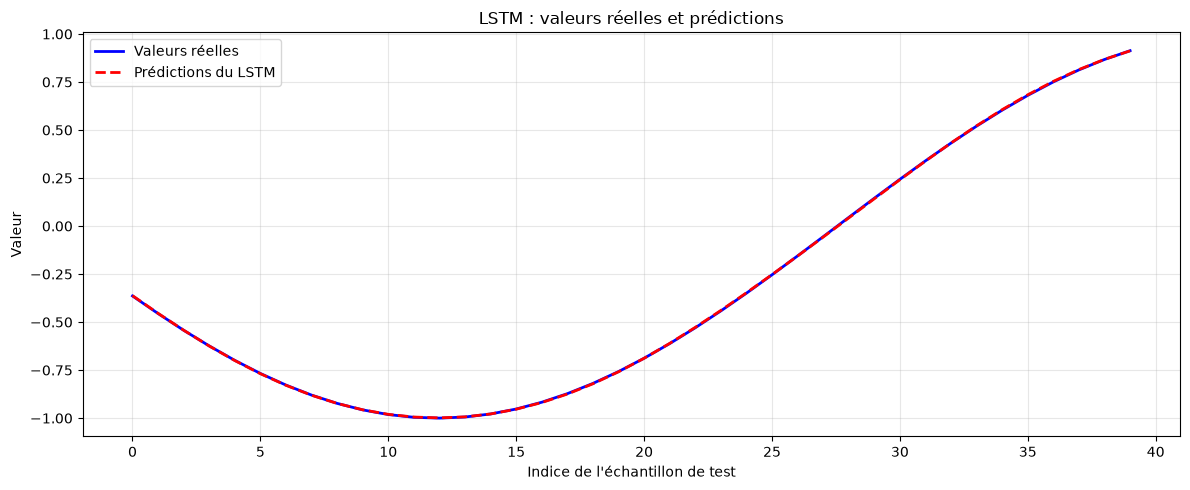

In [2]:
import matplotlib.pyplot as plt

# Convertir les tenseurs en tableaux NumPy
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

# Tracer les deux courbes
plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites,
    label="Prédictions du LSTM",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("LSTM : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()